In [1]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import accuracy_score

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

Dataset Shape: (569, 30)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Create models
svm = SVC()
rf = RandomForestClassifier()
ada = AdaBoostClassifier()

# Train models
svm.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
ada.fit(X_train, y_train)

print("All models trained successfully!")

All models trained successfully!


In [6]:
# Make predictions
svm_pred = svm.predict(X_test_scaled)
rf_pred = rf.predict(X_test)
ada_pred = ada.predict(X_test)

# Calculate accuracy
svm_acc = accuracy_score(y_test, svm_pred)
rf_acc = accuracy_score(y_test, rf_pred)
ada_acc = accuracy_score(y_test, ada_pred)

print("SVM Accuracy:", svm_acc)
print("Random Forest Accuracy:", rf_acc)
print("AdaBoost Accuracy:", ada_acc)

SVM Accuracy: 0.9824561403508771
Random Forest Accuracy: 0.9649122807017544
AdaBoost Accuracy: 0.9649122807017544


In [7]:
# SVM Cross Validation
svm_cv = cross_val_score(svm, X_train_scaled, y_train, cv=5)

# Random Forest Cross Validation
rf_cv = cross_val_score(rf, X_train, y_train, cv=5)

# AdaBoost Cross Validation
ada_cv = cross_val_score(ada, X_train, y_train, cv=5)

print("SVM CV Accuracy:", svm_cv.mean())
print("Random Forest CV Accuracy:", rf_cv.mean())
print("AdaBoost CV Accuracy:", ada_cv.mean())

SVM CV Accuracy: 0.9758241758241759
Random Forest CV Accuracy: 0.956043956043956
AdaBoost CV Accuracy: 0.9802197802197803


In [9]:
# SVM Grid Search
svm_grid = GridSearchCV(SVC(), {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}, cv=5)

# Random Forest Grid Search
rf_grid = GridSearchCV(RandomForestClassifier(), {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}, cv=5)

# AdaBoost Grid Search
ada_grid = GridSearchCV(AdaBoostClassifier(), {
    'n_estimators': [50, 100],
    'learning_rate': [0.1, 1]
}, cv=5)

# Train Grid Search
svm_grid.fit(X_train_scaled, y_train)
rf_grid.fit(X_train, y_train)
ada_grid.fit(X_train, y_train)

print("SVM Best Parameters:", svm_grid.best_params_)
print("Random Forest Best Parameters:", rf_grid.best_params_)
print("AdaBoost Best Parameters:", ada_grid.best_params_)

SVM Best Parameters: {'C': 1, 'kernel': 'rbf'}
Random Forest Best Parameters: {'max_depth': 10, 'n_estimators': 50}
AdaBoost Best Parameters: {'learning_rate': 1, 'n_estimators': 50}


In [10]:
# Make predictions using optimized models
svm_opt = svm_grid.predict(X_test_scaled)
rf_opt = rf_grid.predict(X_test)
ada_opt = ada_grid.predict(X_test)

# Calculate accuracy
svm_opt_acc = accuracy_score(y_test, svm_opt)
rf_opt_acc = accuracy_score(y_test, rf_opt)
ada_opt_acc = accuracy_score(y_test, ada_opt)

print("Optimized SVM Accuracy:", svm_opt_acc)
print("Optimized Random Forest Accuracy:", rf_opt_acc)
print("Optimized AdaBoost Accuracy:", ada_opt_acc)

Optimized SVM Accuracy: 0.9824561403508771
Optimized Random Forest Accuracy: 0.9649122807017544
Optimized AdaBoost Accuracy: 0.9649122807017544


In [11]:
comparison = pd.DataFrame({
    'Model': ['SVM', 'Random Forest', 'AdaBoost'],
    'Before Optimization': [svm_acc, rf_acc, ada_acc],
    'After Optimization': [svm_opt_acc, rf_opt_acc, ada_opt_acc]
})

print(comparison)

           Model  Before Optimization  After Optimization
0            SVM             0.982456            0.982456
1  Random Forest             0.964912            0.964912
2       AdaBoost             0.964912            0.964912


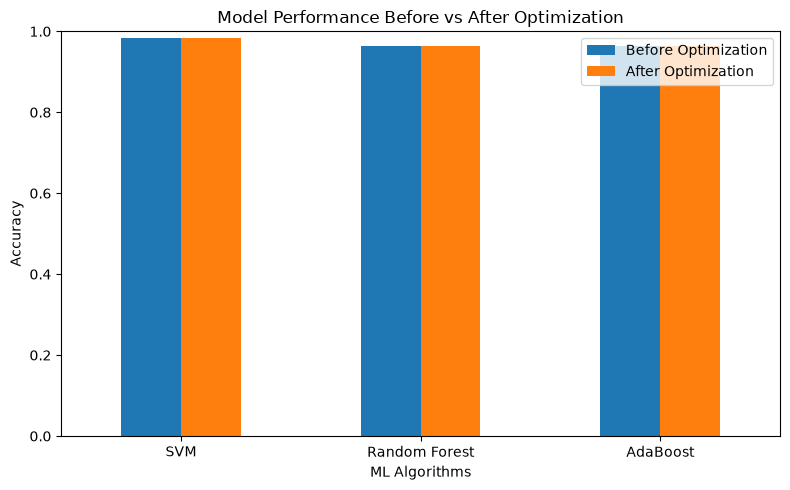

In [12]:
import matplotlib.pyplot as plt

comparison.set_index('Model').plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Model Performance Before vs After Optimization')
plt.ylabel('Accuracy')
plt.xlabel('ML Algorithms')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()